# 03 · Next-meal recommendation, what-if scenarios and budget analysis

Transparent rule-based scoring (see `foodspend_core/recommender.py` and DECISIONS.md). Results are recommendations **from the dataset's meal options**, not verified real-time availability, and are not medical advice.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'backend'))
import pandas as pd, matplotlib.pyplot as plt
from foodspend_core import analytics as A
from foodspend_core.recommender import recommend, simulate, budget_comparison
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = ROOT / 'analysis' / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e1e0d9',
                     'axes.edgecolor': '#c3c2b7', 'font.size': 10, 'figure.dpi': 110})
ds = A.load_processed(ROOT / 'data' / 'processed')
print('SYNTHETIC DATA - generated by analysis/scripts/generate_synthetic_data.py')

SYNTHETIC DATA - generated by analysis/scripts/generate_synthetic_data.py


In [2]:
rec = recommend(ds, meal_type='lunch', goal_key='protein', budget=350)
ctx = rec['context']
print('Goal:', ctx['goal']['goal_name'], '| daily target', ctx['goal']['daily_target'], ctx['goal']['unit'])
print('Lunch target:', ctx['meal_target'], 'g | calorie allowance', ctx['kcal_allowance'], 'kcal | budget Rs', ctx['budget'])
print('Recent 30-day context:', ctx['recent_intake']['goal_status_recent'])
print('Excluded by feedback:', [e['food_name'] + ' (' + e['latest_label'] + ')' for e in rec['excluded_by_feedback']])

Goal: Increase protein toward RDA | daily target 65.5 g/day
Lunch target: 22.9 g | calorie allowance 738 kcal | budget Rs 350.0
Recent 30-day context: {'goal_key': 'protein', 'goal_name': 'Increase protein toward RDA', 'nutrient': 'protein_g', 'direction': 'at_least', 'target': 65.5, 'unit': 'g/day', 'average_logged': 53.0, 'pct_of_target': 80.9, 'status': 'Below target', 'reference_source': 'ICMR-NIN Nutrient Requirements for Indians (2020): protein RDA 0.83 g/kg body weight/day; multiplied by latest recorded weight'}
Excluded by feedback: ['Veg Hakka Noodles (disliked)', 'Green Salad (disliked)', 'Chole Bhature (disliked)', 'Fish Curry Meal (avoid)']


In [3]:
r = rec['recommended']
print('RECOMMENDED:', r['name'])
print('Cost:', r['cost'])
print('Nutrients:', r['nutrients'])
print('Scores:', r['scores'])
print('Confidence:', r['confidence'])
print()
print('\n'.join(r['reasons']))

RECOMMENDED: Home Paneer Bhurji with 2 Roti
Cost: {'items_subtotal': 85.0, 'tax': 0.0, 'fees': 0.0, 'total': 85.0, 'by_vendor': [{'vendor_id': 'V08', 'vendor_name': 'Home Kitchen', 'channel': 'home', 'items_subtotal': 85.0, 'tax': 0.0, 'fees': 0.0, 'fee_basis': 'no delivery fee', 'total': 85.0}]}
Nutrients: {'calories_kcal': 520.0, 'protein_g': 26.0, 'carbs_g': 40.0, 'fat_g': 28.0, 'fiber_g': 5.0}
Scores: {'goal_progress': 1.0, 'secondary': 1.0, 'goal': 1.0, 'preference': 0.785, 'cost': 0.7571, 'total': 0.8869}
Confidence: {'score': 0.9, 'level': 'High', 'factors': ['Nutrient values are synthetic estimates (+/-15% serving-size uncertainty shown)']}

Supplies 26 g protein, 113.4% of the lunch share (22.9 g = 35% of 65.5 g/day) for the goal 'Increase protein toward RDA'.
520 kcal against a lunch allowance of 738 kcal (70.4%; calorie-fit score 1.00).
Estimated cost Rs 85 (incl. tax/fees Rs 0), leaving Rs 265 of the Rs 350 budget (24.3% used).
Home Paneer Bhurji with 2 Roti: mean rating 4.

In [4]:
pd.DataFrame([{'type': a['alternative_type'], 'name': a['name'], 'cost': a['cost']['total'], 'protein_g': a['nutrients']['protein_g'],
               'kcal': a['nutrients']['calories_kcal'], 'total_score': a['scores']['total'], **{f'd_{k}': v for k, v in a['tradeoff'].items()}}
              for a in rec['alternatives']])

,type,name,cost,protein_g,kcal,total_score,d_cost_difference,d_goal_nutrient_difference,d_calorie_difference,d_preference_score_difference,d_total_score_difference
0,substitution,"Home Dal, Rice and Sabzi Thali + Curd (Dahi)",94.08,23.2,611.5,0.8666,9.08,-2.8,91.5,-0.051,-0.020
1,serving_increase,Home Paneer Bhurji with 2 Roti x1.5,127.50,39.0,780.0,0.8542,42.50,13.0,260.0,0.000,-0.033
2,addition,Home Paneer Bhurji with 2 Roti + Banana,91.36,27.3,626.8,0.8846,6.36,1.3,106.8,0.004,-0.002
3,budget_saver,"Home Dal, Rice and Sabzi Thali",75.00,18.0,520.0,0.7950,-10.00,-8.0,0.0,-0.075,-0.092


In [5]:
pd.DataFrame(rec['ranking']).drop(columns='lines')

,rank,name,cost_inr,goal_amount,calories,goal_score,preference_score,cost_score,total_score
0,1,Home Paneer Bhurji with 2 Roti,85.00,26.0,520.0,1.0000,0.7850,0.7571,0.8869
1,2,Home Paneer Bhurji with 2 Roti + Banana,91.36,27.3,626.8,1.0000,0.7894,0.7390,0.8846
2,3,Home Paneer Bhurji with 2 Roti + Curd (Dahi),104.08,31.2,611.5,1.0000,0.7906,0.7026,0.8777
3,4,Home Paneer Bhurji with 2 Roti + Boiled Eggs,99.84,39.0,675.0,1.0000,0.7744,0.7147,0.8753
4,5,"Home Dal, Rice and Sabzi Thali + Curd (Dahi)",94.08,23.2,611.5,1.0000,0.7344,0.7312,0.8666
5,6,Home Paneer Bhurji with 2 Roti + Apple,116.80,26.4,598.0,1.0000,0.7731,0.6663,0.8652
6,7,"Home Dal, Rice and Sabzi Thali + Boiled Eggs",89.84,31.0,675.0,1.0000,0.7181,0.7433,0.8641
7,8,Home Paneer Bhurji with 2 Roti + Roasted Chana,97.72,34.8,667.6,1.0000,0.7137,0.7208,0.8583
8,9,Home Paneer Bhurji with 2 Roti x1.5,127.50,39.0,780.0,0.9831,0.7850,0.6357,0.8542
9,10,"Home Dal, Rice and Sabzi Thali + Roasted Chana",87.72,26.8,667.6,1.0000,0.6575,0.7494,0.8471


## Same question, delivery-only and other goals

In [6]:
rows = []
for src in ['any', 'delivery', 'home']:
    for g in ['protein', 'fiber', 'calories']:
        x = recommend(ds, 'lunch', g, 350, source=src)['recommended']
        rows.append({'source': src, 'goal': g, 'meal': x['name'], 'cost': x['cost']['total'], 'protein_g': x['nutrients']['protein_g'],
                     'fiber_g': x['nutrients']['fiber_g'], 'kcal': x['nutrients']['calories_kcal']})
pd.DataFrame(rows)

,source,goal,meal,cost,protein_g,fiber_g,kcal
0,any,protein,Home Paneer Bhurji with 2 Roti,85.00,26.0,5.0,520.0
1,any,fiber,"Home Dal, Rice and Sabzi Thali + Banana",81.36,19.3,13.1,626.8
2,any,calories,Home Paneer Bhurji with 2 Roti,85.00,26.0,5.0,520.0
3,delivery,protein,Idli Sambar (3 idli) + Boiled Eggs,139.09,24.0,6.0,485.0
4,delivery,fiber,Idli Sambar (3 idli) + Roasted Chana,136.97,19.8,12.8,477.6
5,delivery,calories,Idli Sambar (3 idli) + Boiled Eggs,139.09,24.0,6.0,485.0
6,home,protein,Home Paneer Bhurji with 2 Roti,85.00,26.0,5.0,520.0
7,home,fiber,"Home Dal, Rice and Sabzi Thali + Banana",81.36,19.3,13.1,626.8
8,home,calories,Home Paneer Bhurji with 2 Roti,85.00,26.0,5.0,520.0


## What-if scenarios (recalculated from reference data)
Baseline: a frequently ordered delivery lunch (Paneer Butter Masala with 2 Roti).

In [7]:
base = [{'food_id': 'F004', 'servings': 1}]
scen = {
  'Increase serving to 2': [{'op': 'set_servings', 'food_id': 'F004', 'servings': 2}],
  'Add boiled eggs (previously purchased)': [{'op': 'add', 'food_id': 'F023', 'servings': 1}],
  'Substitute with Grilled Chicken Salad Bowl': [{'op': 'substitute', 'food_id': 'F004', 'with_food_id': 'F008'}],
  'Substitute with home dal thali + curd': [{'op': 'substitute', 'food_id': 'F004', 'with_food_id': 'F027'}, {'op': 'add', 'food_id': 'F021'}],
}
rows = []
for name, ops in scen.items():
    s = simulate(ds, base, ops, meal_type='lunch', goal_key='protein', budget=350)
    rows.append({'scenario': name, 'baseline_cost': s['baseline']['cost']['total'], 'modified_cost': s['modified']['cost']['total'],
                 'cost_diff': s['differences']['cost'], **{f'd_{k}': v for k, v in s['differences']['nutrients'].items()},
                 'within_budget': s['verdict']['modified_within_budget'], 'verdict': s['verdict']['goal_direction']})
scen_df = pd.DataFrame(rows); scen_df

,scenario,baseline_cost,modified_cost,cost_diff,d_calories_kcal,d_protein_g,d_carbs_g,d_fat_g,d_fiber_g,within_budget,verdict
0,Increase serving to 2,307.75,575.50,267.75,720.0,26.0,60.0,42.0,6.0,False,The change moves toward the goal 'Increase pro...
1,Add boiled eggs (previously purchased),307.75,322.59,14.84,155.0,13.0,1.1,11.0,0.0,True,The change moves toward the goal 'Increase pro...
2,Substitute with Grilled Chicken Salad Bowl,307.75,349.75,42.00,-310.0,12.0,-38.0,-24.0,1.0,True,The change moves toward the goal 'Increase pro...
3,Substitute with home dal thali + curd,307.75,94.08,-213.67,-108.5,-2.8,32.0,-25.1,4.0,True,The change moves away from the goal 'Increase ...


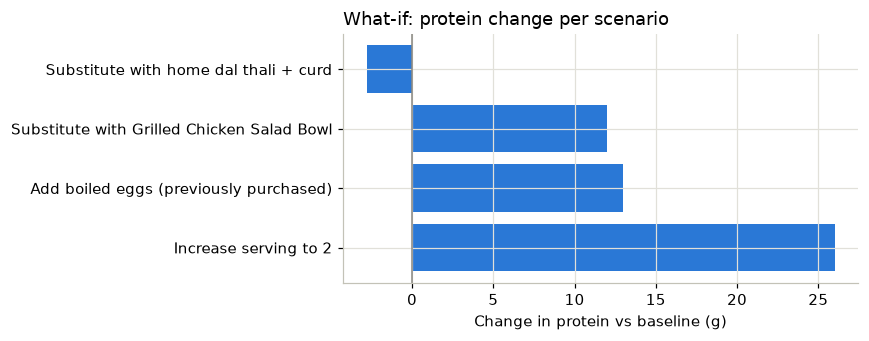

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(scen_df.scenario, scen_df.d_protein_g, color=SERIES[0])
ax.axvline(0, color='#898781', lw=1); ax.set_xlabel('Change in protein vs baseline (g)')
ax.set_title('What-if: protein change per scenario', loc='left')
plt.tight_layout(); fig.savefig(FIG/'whatif_protein.png'); plt.show()

## Custom budget analysis

In [9]:
rows = []
for b in [100, 150, 250, 350, 500, 1000]:
    bc = budget_comparison(ds, b, 'lunch', 'protein', source='delivery')
    o = bc['options'][0] if bc['options'] else None
    rows.append({'budget': b, 'feasible': bc['feasible_count'], 'top_option': o and o['name'], 'cost': o and o['cost']['total'],
                 'remaining': o and o['budget']['remaining'], 'utilization_pct': o and o['budget']['utilization_pct'],
                 'protein_g': o and o['nutrients']['protein_g']})
pd.DataFrame(rows)

,budget,feasible,top_option,cost,remaining,utilization_pct,protein_g
0,100,0,NaN,NaN,NaN,NaN,NaN
1,150,5,Idli Sambar (3 idli) + Boiled Eggs,139.09,10.91,92.7,24.0
2,250,37,Idli Sambar (3 idli) + Boiled Eggs,139.09,110.91,55.6,24.0
3,350,108,Idli Sambar (3 idli) + Boiled Eggs,139.09,210.91,39.7,24.0
4,500,139,Idli Sambar (3 idli) + Boiled Eggs,139.09,360.91,27.8,24.0
5,1000,186,Idli Sambar (3 idli) + Boiled Eggs,139.09,860.91,13.9,24.0


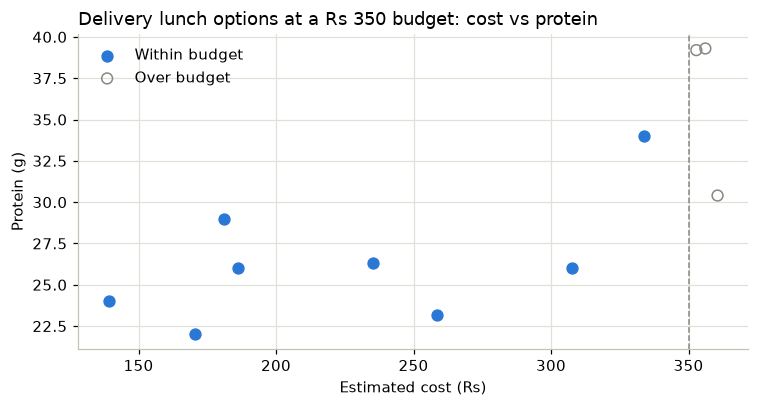

Spearman(cost, protein) among feasible options: 0.47


In [10]:
bc = budget_comparison(ds, 350, 'lunch', 'protein', source='delivery')
opts = pd.DataFrame([{'name': o['name'], 'cost': o['cost']['total'], 'protein': o['nutrients']['protein_g']} for o in bc['options']])
over = pd.DataFrame([{'name': o['name'], 'cost': o['cost']['total'], 'protein': o['nutrients']['protein_g']} for o in bc['nearest_over_budget']])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(opts.cost, opts.protein, color=SERIES[0], label='Within budget', s=50)
if len(over): ax.scatter(over.cost, over.protein, facecolors='none', edgecolors='#898781', label='Over budget', s=50)
ax.axvline(350, ls='--', color='#898781', lw=1)
ax.set_xlabel('Estimated cost (Rs)'); ax.set_ylabel('Protein (g)')
ax.set_title('Delivery lunch options at a Rs 350 budget: cost vs protein', loc='left'); ax.legend(frameon=False)
plt.tight_layout(); fig.savefig(FIG/'budget_scatter.png'); plt.show()
print('Spearman(cost, protein) among feasible options:', round(opts[['cost','protein']].rank().corr().iloc[0,1], 2))

## Sensitivity to ranking weights

In [11]:
presets = {'balanced': None, 'goal-first': {'goal': .7, 'preference': .2, 'cost': .1},
           'preference-first': {'goal': .3, 'preference': .6, 'cost': .1}, 'cost-first': {'goal': .3, 'preference': .2, 'cost': .5}}
pd.DataFrame([{'preset': k, 'recommended (delivery)': recommend(ds, 'lunch', 'protein', 350, weights=w, source='delivery')['recommended']['name']}
              for k, w in presets.items()])

,preset,recommended (delivery)
0,balanced,Idli Sambar (3 idli) + Boiled Eggs
1,goal-first,Idli Sambar (3 idli) + Boiled Eggs
2,preference-first,Chicken Biryani
3,cost-first,Idli Sambar (3 idli) + Boiled Eggs
